In [38]:
from astropy import units
from astropy.time import Time

from matplotlib import pyplot

from src.selflensing.fitting import self_lensing_system_from_fit
from src.selflensing.generators import LightcurveGenerator, RVGenerator
from src.selflensing.models import SelfLensingSystem

In [39]:
LENSING_METHOD = 'IntegratedWittMao'

In [40]:
sls = SelfLensingSystem(
    a=28 * units.AU,
    b=0 * units.dimensionless_unscaled,
    Macc=10*units.M_sun,
    Mcomp=4*units.M_sun,
    Rcomp=10*units.R_sun,
    e=0 * units.dimensionless_unscaled,
)
sls.porb

<Quantity 14463.43526446 d>

In [41]:
sls.rE(), sls.tau_eff

(<Quantity 0.71496508 solRad>, <Quantity 8.19314995 d>)

In [42]:
start_time = Time("2025-01-01")
end_time = Time("2026-01-01")
peak_time = Time("2025-02-01")

In [43]:
lcg = LightcurveGenerator(sls, start_time=start_time, end_time=end_time, peak_time=peak_time, ev=False, db=False, sl=True, lensing_method=LENSING_METHOD)
rvg = RVGenerator(sls, start_time=start_time, end_time=end_time, peak_time=peak_time)

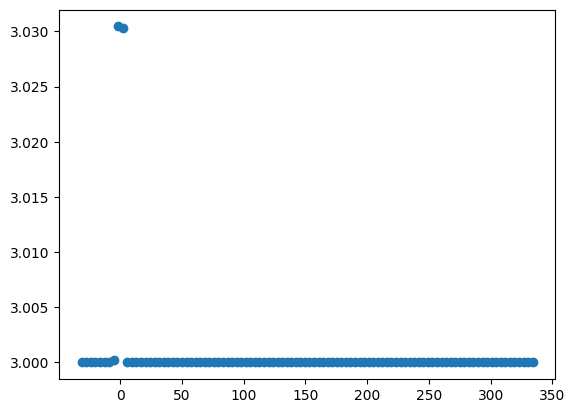

In [44]:
pyplot.scatter((lcg.time_offsets), lcg.flux_array)

In [45]:
import numpy
peak_mag = numpy.max(lcg.timeseries['flux']) / numpy.median(lcg.timeseries['flux'])
min_mag = peak_mag * 0.999
max_mag = peak_mag * 1.001
min_mag, peak_mag, max_mag

(<Quantity 1.0091415>, <Quantity 1.01015165>, <Quantity 1.0111618>)

In [46]:
import rustlens
rustlens.witt_mao_magnification([0], sls.rE().value, sls.Rcomp.value)

[1.0101717687491292]

In [47]:
non_detection_times = [t for t in lcg.time_offsets if t not in lcg.peak_time_offsets]

In [48]:
sls.tau_eff, sls.rE(), sls.b

(<Quantity 8.19314995 d>, <Quantity 0.71496508 solRad>, <Quantity 0.>)

In [49]:
from src.selflensing.calc import estimate_porb

p = estimate_porb(sls.tau_eff, min_mag, max_mag, sls.Rcomp)
p

[[  2610.3096       2610.3096       2610.3097     ...   5491.461
    5501.9712       5512.4905    ]
 [  5220.61923737   5220.61924747   5220.6193798  ...  10982.92202323
   11003.94239798  11024.98098687]
 [  7830.92887475   7830.92889495   7830.9290596  ...  16474.38304646
   16505.91359596  16537.47147374]
 ...
 [255810.34442525 255810.34540505 255810.3486404  ... 538163.18025354
  539193.17740404 540224.06772626]
 [258420.65406263 258420.65505253 258420.6583202  ... 543654.64127677
  544695.14860202 545736.55821313]
 [261030.9637     261030.9647     261030.968      ... 549146.1023
  550197.1198     551249.0487    ]]
porb_bins (100,) [   1000.            1072.26722201    1149.7569954     1232.84673944
    1321.94114847    1417.47416293    1519.91108295    1629.75083462
    1747.52840001    1873.81742286    2009.23300257    2154.43469003
    2310.12970008    2477.07635599    2656.08778295    2848.03586844
    3053.85550883    3274.54916288    3511.19173422    3764.93580679
    4037.01

([np.float64(1000.0),
  np.float64(1072.2672220103232),
  np.float64(1149.7569953977356),
  np.float64(1232.8467394420659),
  np.float64(1321.9411484660286),
  np.float64(1417.4741629268049),
  np.float64(1519.9110829529332),
  np.float64(1629.7508346206434),
  np.float64(1747.5284000076829),
  np.float64(1873.817422860383),
  np.float64(2009.2330025650479),
  np.float64(2154.4346900318847),
  np.float64(2310.1297000831605),
  np.float64(2477.0763559917114),
  np.float64(2656.0877829466867),
  np.float64(2848.035868435802),
  np.float64(3053.8555088334156),
  np.float64(3274.5491628777286),
  np.float64(3511.191734215131),
  np.float64(3764.9358067924672),
  np.float64(4037.017258596554),
  np.float64(4328.761281083057),
  np.float64(4641.588833612782),
  np.float64(4977.023564332114),
  np.float64(5336.699231206313),
  np.float64(5722.3676593502205),
  np.float64(6135.907273413176),
  np.float64(6579.332246575683),
  np.float64(7054.8023107186455),
  np.float64(7564.633275546291),
  n

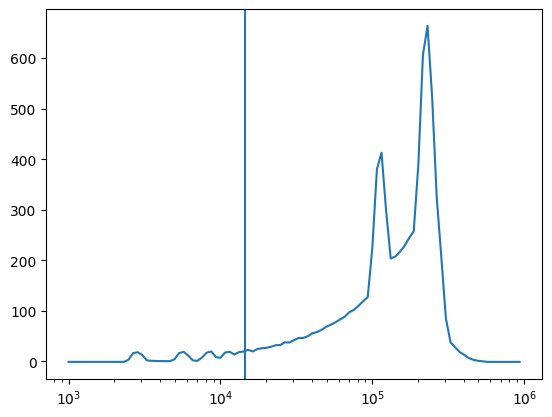

In [ ]:
pyplot.plot(p[0], p[2])
pyplot.xscale('log')
pyplot.axvline(sls.porb.value)
# Could this just be a scaling issue?

In [51]:
from src.selflensing.calc import eliminate_times
sls.porb, eliminate_times(p, sls.tau_eff, non_detection_times)

ValueError: too many values to unpack (expected 2)

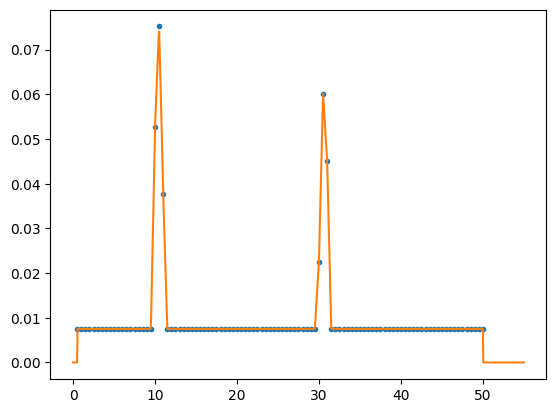

In [ ]:
import matplotlib.pyplot as plt
import numpy
from src.selflensing.calc import LENS_MASS_DIST, lens_mass_pdist

x = numpy.linspace(0, 55, 1000)
_ = plt.plot(LENS_MASS_DIST[0,:], LENS_MASS_DIST[1,:], '.', x, lens_mass_pdist(1000, 0, 55), '-')
plt.show()

In [ ]:
LENS_MASS_DIST[0,:]

array([ 0.5,  1. ,  1.5,  2. ,  2.5,  3. ,  3.5,  4. ,  4.5,  5. ,  5.5,
        6. ,  6.5,  7. ,  7.5,  8. ,  8.5,  9. ,  9.5, 10. , 10.5, 11. ,
       11.5, 12. , 12.5, 13. , 13.5, 14. , 14.5, 15. , 15.5, 16. , 16.5,
       17. , 17.5, 18. , 18.5, 19. , 19.5, 20. , 20.5, 21. , 21.5, 22. ,
       22.5, 23. , 23.5, 24. , 24.5, 25. , 25.5, 26. , 26.5, 27. , 27.5,
       28. , 28.5, 29. , 29.5, 30. , 30.5, 31. , 31.5, 32. , 32.5, 33. ,
       33.5, 34. , 34.5, 35. , 35.5, 36. , 36.5, 37. , 37.5, 38. , 38.5,
       39. , 39.5, 40. , 40.5, 41. , 41.5, 42. , 42.5, 43. , 43.5, 44. ,
       44.5, 45. , 45.5, 46. , 46.5, 47. , 47.5, 48. , 48.5, 49. , 49.5,
       50. ])

In [ ]:
import numpy

probs = numpy.array([0.1, 0.2, 0.1, 0.2, 0.05, 0.05, 0.05, 0.05, 0.1, 0.1])
a = numpy.linspace(numpy.array([1,2,3,4]), numpy.array([5,6,7,8]), 10)
a

array([[1.        , 2.        , 3.        , 4.        ],
       [1.44444444, 2.44444444, 3.44444444, 4.44444444],
       [1.88888889, 2.88888889, 3.88888889, 4.88888889],
       [2.33333333, 3.33333333, 4.33333333, 5.33333333],
       [2.77777778, 3.77777778, 4.77777778, 5.77777778],
       [3.22222222, 4.22222222, 5.22222222, 6.22222222],
       [3.66666667, 4.66666667, 5.66666667, 6.66666667],
       [4.11111111, 5.11111111, 6.11111111, 7.11111111],
       [4.55555556, 5.55555556, 6.55555556, 7.55555556],
       [5.        , 6.        , 7.        , 8.        ]])

In [ ]:
bins = numpy.arange(0, 10)
bins

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [ ]:
(numpy.digitize(a, bins) == 3).nonzero()[0]

array([0, 1, 2, 3, 4])

In [ ]:
probs

array([0.1 , 0.2 , 0.1 , 0.2 , 0.05, 0.05, 0.05, 0.05, 0.1 , 0.1 ])

In [ ]:
b = numpy.tile(probs, a.shape).T
b

array([[0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 ],
       [0.2 , 0.2 , 0.2 , 0.2 , 0.2 , 0.2 , 0.2 , 0.2 , 0.2 , 0.2 ],
       [0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 ],
       [0.2 , 0.2 , 0.2 , 0.2 , 0.2 , 0.2 , 0.2 , 0.2 , 0.2 , 0.2 ],
       [0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05],
       [0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05],
       [0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05],
       [0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05],
       [0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 ],
       [0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 ],
       [0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 ],
       [0.2 , 0.2 , 0.2 , 0.2 , 0.2 , 0.2 , 0.2 , 0.2 , 0.2 , 0.2 ],
       [0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 ],
       [0.2 , 0.2 , 0.2 , 0.2 , 0.2 , 0.2 , 0.2 , 0.2 , 0.2 , 0.2 ],
       [0.05, 0.05, 0.05, 0.05, 0.

In [ ]:
a[numpy.where((a < 4) & (a >= 3))]

array([3.        , 3.44444444, 3.88888889, 3.33333333, 3.77777778,
       3.22222222, 3.66666667])

In [ ]:
(a < 4) & (a >= 3)

array([[False, False,  True, False],
       [False, False,  True, False],
       [False, False,  True, False],
       [False,  True, False, False],
       [False,  True, False, False],
       [ True, False, False, False],
       [ True, False, False, False],
       [False, False, False, False],
       [False, False, False, False],
       [False, False, False, False]])

In [ ]:
numpy.where((a < 4) & (a >= 3))

(array([0, 1, 2, 3, 4, 5, 6]), array([2, 2, 2, 1, 1, 0, 0]))

In [ ]:
b[numpy.where((a < 3) & (a >= 2))], sum(b[numpy.where((a < 3) & (a >= 2))])

(array([0.1 , 0.2 , 0.1 , 0.2 , 0.05]), np.float64(0.6500000000000001))

In [ ]:
probs[numpy.where((a < 3) & (a >= 2))[0]]

array([0.1 , 0.2 , 0.1 , 0.2 , 0.05])

In [ ]:
numpy.sum(b[numpy.where((a < 3) & (a >= 2))]) - numpy.prod(b[numpy.where((a < 3) & (a >= 2))])

np.float64(0.6499800000000001)

In [ ]:
sls_fit, sampler = self_lensing_system_from_fit(
    rv_times=rvg.times,
    observed_rv=rvg.rv,
    observed_rv_err=1 * rvg.units,
    lc_times=lcg.times,
    observed_lc=lcg.flux_array,
    observed_lc_err=1 * lcg.units,
    peak_time=peak_time,
    Mcomp=sls.Mcomp,
    Rcomp=sls.Rcomp,
    Teff=sls.Teff,
    nsteps=5000,
    nwalkers=20,
    burn=10,
    lensing_method=LENSING_METHOD,
)
lcg_fit = LightcurveGenerator(sls_fit, start_time=start_time, end_time=end_time, peak_time=peak_time, lensing_method=LENSING_METHOD)
rvg_fit = RVGenerator(sls_fit, start_time=start_time, end_time=end_time, peak_time=peak_time)

/Users/adam/Library/Caches/pypoetry/virtualenvs/selflensing-OJwetTlj-py3.13/lib/python3.13/site-packages/astropy/units/quantity.py:659: RuntimeWarning: invalid value encountered in divide
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


ValueError: Probability function returned NaN

In [ ]:
sls.a, sls.Macc, sls.b, sls.e, sls.periapsis_phase, sls.porb

(<Quantity 20. AU>,
 <Quantity 1.3 solMass>,
 <Quantity 0.>,
 <Quantity 0.>,
 <Quantity 0. rad>,
 <Quantity 14190.75446116 d>)

In [ ]:
sls_fit.a, sls_fit.Macc, sls_fit.b, sls_fit.e, sls_fit.periapsis_phase, sls_fit.porb

(<Quantity 4.5537544 AU>,
 <Quantity 0.5 solMass>,
 <Quantity 9.98771027>,
 <Quantity 0.76710854>,
 <Quantity 4.04549704 rad>,
 <Quantity 1673.19507101 d>)

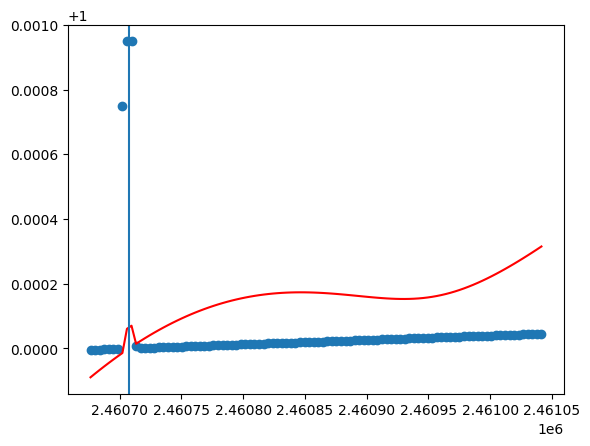

In [ ]:
pyplot.scatter(lcg.times.jd, lcg.flux_array)
pyplot.plot(lcg_fit.times.jd, lcg_fit.flux_array, c='red')
pyplot.axvline(peak_time.jd)

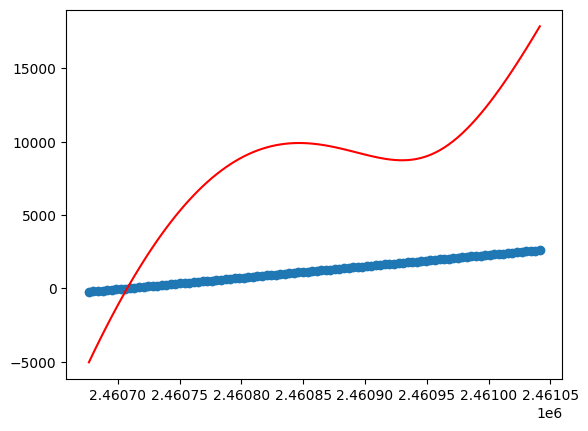

In [ ]:
pyplot.scatter(rvg.times.jd, rvg.rv)
pyplot.plot(rvg_fit.times.jd, rvg_fit.rv, c='red')

Text(0.5, 0, 'step number')

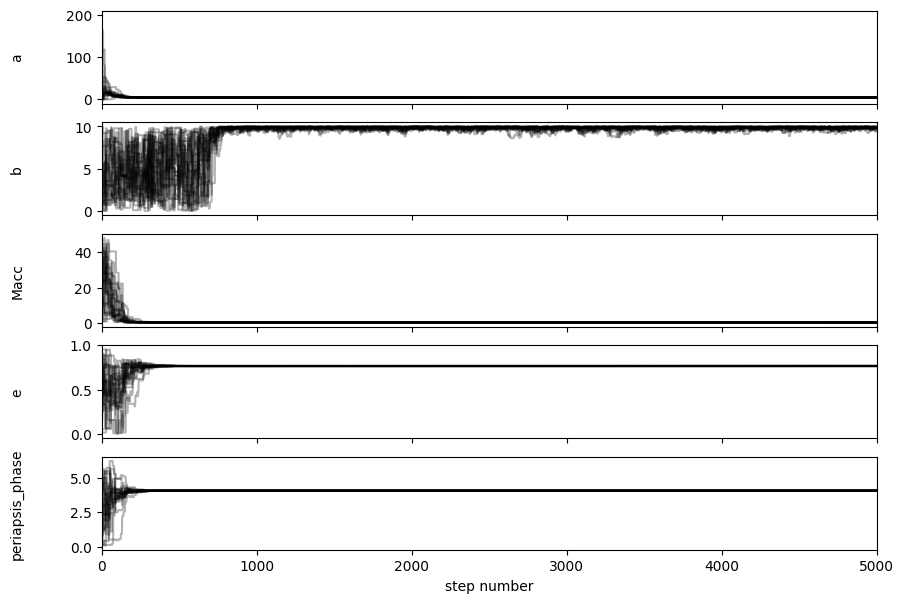

In [ ]:
from matplotlib import pyplot as plt
labels = ["a", "b", "Macc", 'e', 'periapsis_phase']
fig, axes = plt.subplots(len(labels), figsize=(10, 7), sharex=True)
samples = sampler.get_chain()#discard=100)
flat_samples = sampler.get_chain(flat=True)
for i in range(len(labels)):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number")

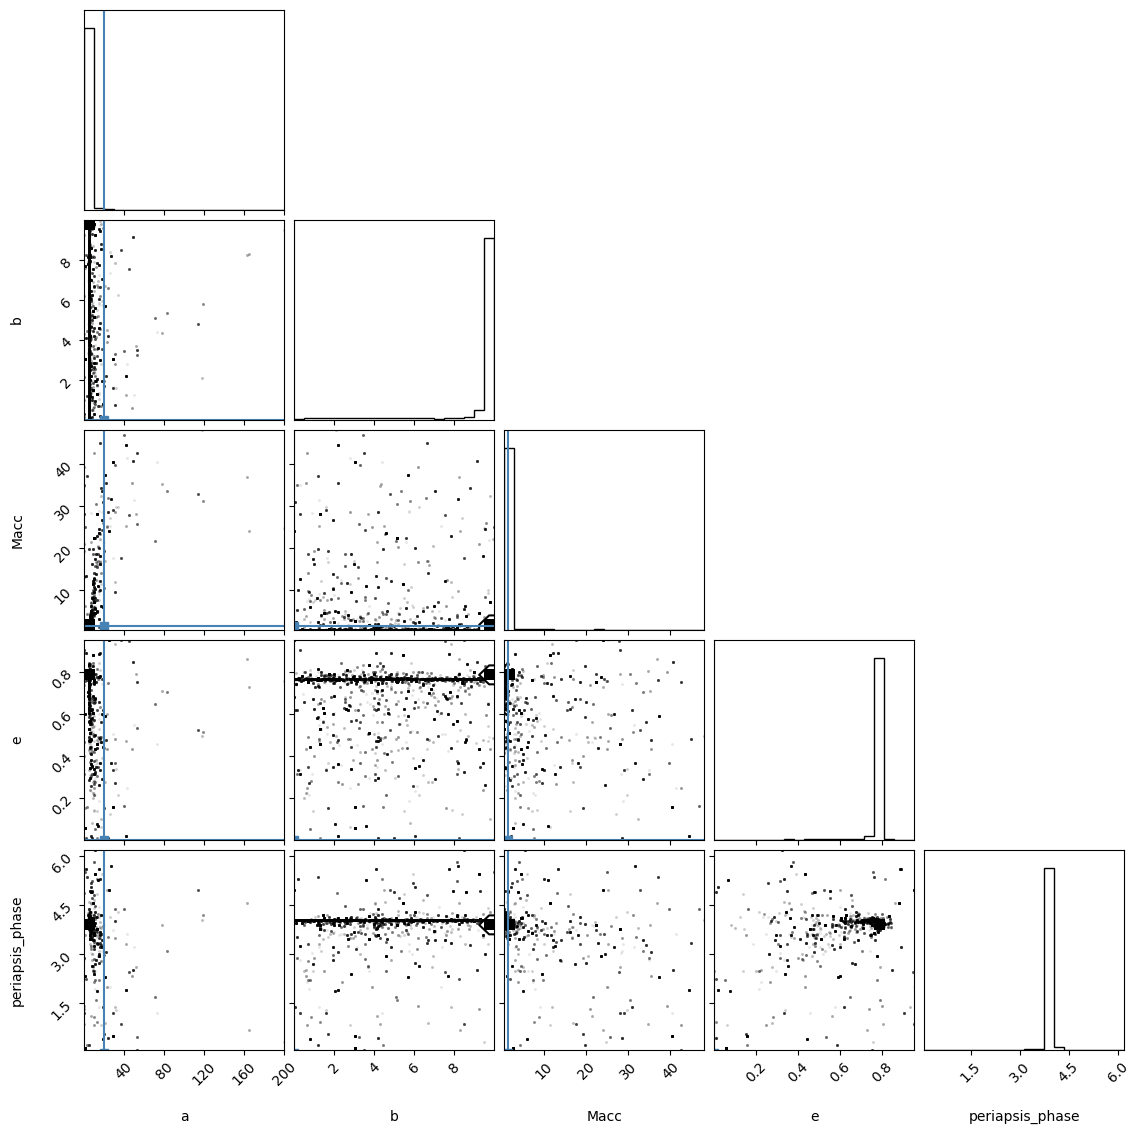

In [ ]:
import corner

fig = corner.corner(
    flat_samples, labels=labels, truths=[sls.a.value, sls.b.value, sls.Macc.value, sls.e.value, sls.periapsis_phase.value]
)